# Tema 14 · Agrupar sin etiquetas: clustering

Descubrir grupos en los datos cuando nadie dijo qué buscar.

Este cuaderno es el tema 14 de la [ruta de aprendizaje de la OBIA](https://iabolivia.org/ruta/): la teoría y los ejercicios de [la página del tema](https://iabolivia.org/ruta/14-agrupar-sin-etiquetas-clustering/), con todo su código. Ejecuta las celdas en orden, de arriba abajo (o *Entorno de ejecución → Ejecutar todas*).

Debajo de cada celda está la salida que dio cuando se escribió el tema. Al ejecutarla, la tuya puede variar en los últimos decimales. Las actividades interactivas están en la página del tema.

# Teoría

## La pregunta

Una heladería guarda, de cada cliente con tarjeta, cuánto gasta al mes y cuántas veces viene. Al dueño le gustaría saber qué **tipos** de clientes tiene, para pensar promociones distintas para cada uno. Pero nadie le dijo cuáles son esos tipos, ni cuántos hay. No existe una columna «tipo de cliente» con la respuesta correcta.

Hasta ahora, todos los modelos de la ruta aprendieron de ejemplos **con respuesta**: la nota del examen, si el pasajero sobrevivió, la especie de la flor. Aquí no hay respuesta. Lo único que podemos hacer es mirar los datos y preguntarnos: ¿hay puntos que se juntan entre sí y se separan de los demás? Buscar esos grupos se llama **clustering** (agrupamiento), y es el ejemplo más conocido del **aprendizaje no supervisado**.

En este tema vas a:

- programar **K-means** desde cero y entender sus dos pasos, asignar y mover;
- elegir cuántos grupos buscar con el **método del codo** y el **coeficiente de silueta**;
- usar **DBSCAN** para grupos de formas raras y para marcar puntos sueltos como ruido;
- construir y leer un **dendrograma** (clustering jerárquico);
- reconocer cuándo el **clustering espectral** separa formas que K-means no puede;
- agrupar con probabilidades con una **mezcla de gaussianas**, estimar una densidad con **KDE** y usarla para **detectar anomalías**;
- comprimir los colores de una foto con K-means.

Necesitas lo del tema 3 (arreglos, broadcasting, una imagen como arreglo) y lo del tema 10 (por qué y cómo escalar las columnas, `GridSearchCV`). Para la sección de mezclas y densidad, también la distribución normal y el logaritmo del tema 5 y la validación cruzada del tema 7.

## Actividad: K-means a mano

Antes de programar nada, agrupa tú. En el dibujo hay puntos sin ningún grupo. Toca el dibujo para poner **centroides** (el centro de cada grupo; puedes poner hasta cuatro) o usa el botón «Agregar centroide». Después alterna los dos botones:

- **Asignar**: cada punto se une al centroide más cercano y toma su forma (círculo, cuadrado, triángulo o rombo).
- **Mover**: cada centroide se va al promedio de los puntos de su grupo.

Debajo verás la **inercia**: la suma de las distancias al cuadrado de cada punto a su centroide. Es el error que K-means intenta bajar.

> **Actividad interactiva:** está en la [página del tema](https://iabolivia.org/ruta/14-agrupar-sin-etiquetas-clustering/teoria/). Ábrela en el navegador para usarla.
Prueba esto, en orden:

1. Pon cuatro centroides, uno en cada mancha, y pulsa Asignar y Mover hasta que nada cambie. Anota la inercia.
2. Pulsa «Quitar centroides» y pon los cuatro **todos en la misma mancha**. Repite Asignar y Mover. ¿Llegas a los mismos grupos? ¿Y a la misma inercia?
3. Prueba con dos y con tres centroides. ¿La inercia sube o baja? ¿Con cuántos centroides queda más baja?
4. Cambia a los datos «Lunas» y haz K-means con dos centroides. ¿Separa las dos lunas?
5. Cambia al modo DBSCAN. Pasa el puntero (o mueve el círculo con las flechas) y mira cuántos vecinos caben en el círculo. Mueve el radio *eps*: ¿qué pasa cuando es muy chico? ¿Y muy grande?

Lo que acabas de hacer es K-means completo: **asignar al más cercano y mover al promedio, una y otra vez**. Y viste sus dos debilidades: el resultado depende de dónde empiezas, y solo sabe encontrar grupos redondos.

## Aprender sin etiquetas

En el aprendizaje **supervisado** cada ejemplo trae una característica *x* y un objetivo *y*, y el modelo aprende a predecir *y*. En el **no supervisado** solo hay *x*: el modelo busca estructura en los datos mismos. Agrupar es una forma de hacerlo; reducir dimensiones (tema 15) es otra.

Como no hay respuesta correcta, «buen grupo» necesita una definición. La más común: **los puntos de un mismo grupo están cerca entre sí y lejos de los de otros grupos**. Todo depende, entonces, de cómo medimos la cercanía. Usaremos la **distancia euclidiana** (la de la regla, que calculaste en el tema 3), y eso trae la advertencia del tema 10: si una columna está en bolivianos y otra en años, la de números grandes manda en la distancia. **Antes de agrupar datos reales hay que escalar las columnas.** Lo vas a comprobar en los ejercicios.

Para aprender los métodos usaremos datos **sintéticos**: `make_blobs` de scikit-learn genera puntos alrededor de unos centros, como manchas. Nosotros sabemos de qué mancha salió cada punto (`y_verdad`), pero el algoritmo no lo va a ver: solo recibe `X`. Así podremos comprobar si encuentra los grupos.

Forma de X: (300, 2)
Primeros puntos: [[9.4, -1.3], [-0.5, -8.4], [8.1, 1.8]]


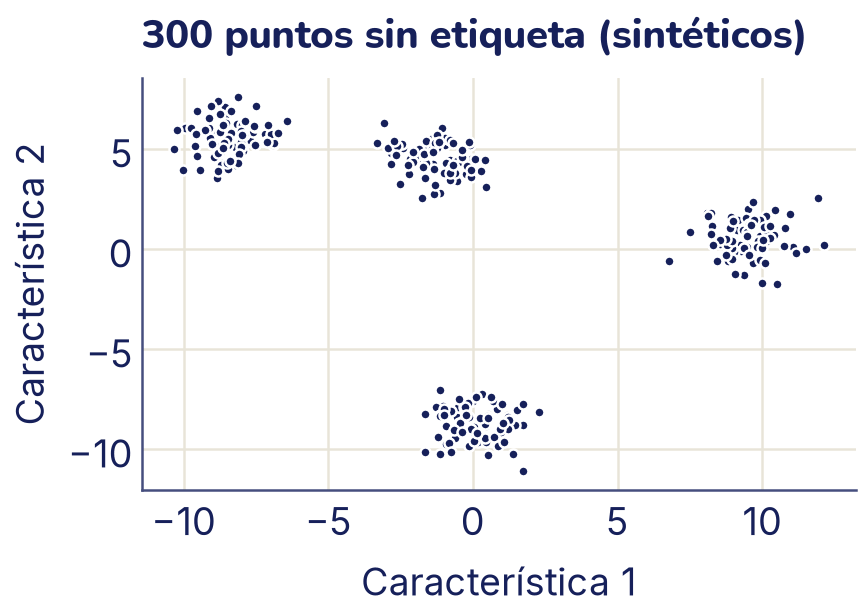

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs

# 300 puntos sintéticos alrededor de 4 centros
X, y_verdad = make_blobs(n_samples=300, centers=4, cluster_std=0.9,
                         random_state=7)
print("Forma de X:", X.shape)
print("Primeros puntos:", X[:3].round(1).tolist())

plt.scatter(X[:, 0], X[:, 1], s=16)
plt.xlabel("Característica 1")
plt.ylabel("Característica 2")
plt.title("300 puntos sin etiqueta (sintéticos)")
plt.show()

Tú ves cuatro manchas sin esfuerzo. El reto es escribir una receta que las encuentre sola, también cuando hay 10 columnas y no se pueden dibujar.

## K-means: asignar y mover

K-means busca **k** grupos (el número *k* lo eliges tú). Cada grupo tiene un **centroide**, un punto que lo representa. La receta:

0. Elegir *k* centroides iniciales; por ejemplo, *k* puntos de los datos al azar.
1. **Asignar**: cada punto va al grupo del centroide más cercano.
2. **Mover**: cada centroide se reemplaza por el promedio de los puntos de su grupo.
3. Repetir 1 y 2 hasta que los centroides dejen de moverse.

¿Qué está optimizando? La **inercia**: la suma, sobre todos los puntos, de la distancia al cuadrado a su centroide.

$$\text{inercia} = \sum_{i = 1}^{n} {\| {\mathbf{x}}_{i} - {\mathbf{c}}_{g ( i )} \|}^{2}$$

Aquí **x**<sub>i</sub> es el punto *i* y **c**<sub>g(i)</sub> es el centroide del grupo al que pertenece. Los dos pasos bajan la inercia (o la dejan igual), por eso el método siempre termina:

- Al **asignar**, cada punto elige el centroide más cercano: su término de la suma no puede subir.
- Al **mover**, el promedio es justo el punto que hace mínima la suma de distancias al cuadrado de un grupo (es la misma razón por la que, en el tema 5, la media minimizaba el error cuadrático).

En NumPy cabe en unas 15 líneas. El truco está en calcular de una vez la distancia de **cada punto a cada centroide** con broadcasting: `X[:, None, :]` tiene forma (300, 1, 2) y `centroides[None, :, :]`, forma (1, 4, 2); al restarlos queda (300, 4, 2), y la norma sobre el último eje da una tabla de distancias de (300, 4).

In [ ]:
def kmeans(X, centroides, pasos=100):
    """K-means desde unos centroides iniciales.

    Devuelve el grupo de cada punto, los centroides finales
    y la lista de centroides de cada vuelta.
    """
    k = len(centroides)
    historial = [centroides]
    for _ in range(pasos):
        # 1) Asignar: distancia de cada punto a cada centroide, (n, k)
        d = np.linalg.norm(X[:, None, :] - centroides[None, :, :], axis=2)
        grupo = d.argmin(axis=1)
        # 2) Mover: cada centroide va al promedio de su grupo
        #    (si un grupo quedó vacío, su centroide no se mueve)
        nuevos = np.array([X[grupo == j].mean(axis=0) if np.any(grupo == j)
                           else centroides[j] for j in range(k)])
        if np.allclose(nuevos, centroides):   # ya no se mueven: listo
            break
        centroides = nuevos
        historial.append(centroides)
    return grupo, centroides, historial

def inercia(X, grupo, centroides):
    """Suma de las distancias al cuadrado de cada punto a su centroide."""
    return np.sum((X - centroides[grupo]) ** 2)

rng = np.random.default_rng(6)
# Cuatro puntos de los datos, al azar, como centroides iniciales
iniciales = X[rng.choice(len(X), size=4, replace=False)]
grupo, centroides, historial = kmeans(X, iniciales)

print("Vueltas hasta que los centroides se quedaron quietos:",
      len(historial) - 1)
print("Centroides finales:")
print(centroides.round(2))
print(f"Inercia final: {inercia(X, grupo, centroides):.1f}")
print("Puntos por grupo:", np.bincount(grupo))

Vueltas hasta que los centroides se quedaron quietos: 3
Centroides finales:
[[ 0.09 -8.71]
 [ 9.52  0.53]
 [-8.44  5.49]
 [-1.31  4.54]]
Inercia final: 462.8
Puntos por grupo: [75 75 75 75]


`centroides[grupo]` usa el arreglo `grupo` como índice: arma una tabla de (300, 2) con el centroide de cada punto, para restarla de `X` de una sola vez. Los cuatro grupos tienen 75 puntos cada uno, como las manchas que generamos.

Para dibujar varios grupos usaremos una función que les da un color **y una forma** distinta (círculo, cuadrado, triángulo, rombo). La forma ayuda a distinguirlos aunque los colores se parezcan o la figura se imprima en blanco y negro. Los centroides finales van en coral.

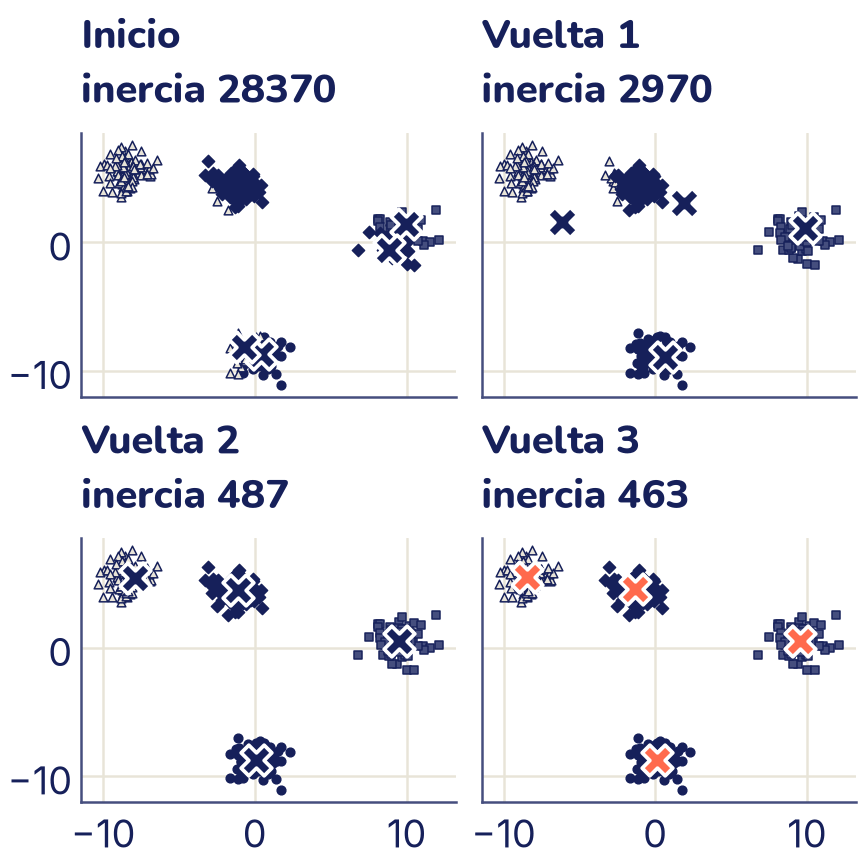

In [ ]:
FORMAS = ["o", "s", "^", "D"]          # círculo, cuadrado, triángulo, rombo
COLORES = ["C0", "C2", "C3", "C0"]

def dibujar_grupos(eje, X, grupo, s=14):
    """Un color y una forma por grupo; el ruido (grupo -1) va como x."""
    for g in np.unique(grupo):
        parte = X[grupo == g]
        if g == -1:
            eje.scatter(parte[:, 0], parte[:, 1], s=s, marker="x",
                        color="C2", linewidths=1)
        else:
            eje.scatter(parte[:, 0], parte[:, 1], s=s, marker=FORMAS[g % 4],
                        color=COLORES[g % 4], edgecolors="C0",
                        linewidths=0.6)

fig, ejes = plt.subplots(2, 2, figsize=(4.8, 4.8),
                         sharex=True, sharey=True)
for vuelta, eje in enumerate(ejes.flat):
    c = historial[vuelta]
    # Asignar cada punto al centroide de esta vuelta
    g = np.linalg.norm(X[:, None, :] - c[None, :, :], axis=2).argmin(axis=1)
    dibujar_grupos(eje, X, g, s=12)
    final = vuelta == len(historial) - 1
    eje.scatter(c[:, 0], c[:, 1], marker="X", s=150, linewidths=1.5,
                color="C1" if final else "C0", edgecolors="white")
    nombre = "Inicio" if vuelta == 0 else f"Vuelta {vuelta}"
    eje.set_title(f"{nombre}\ninercia {inercia(X, g, c):.0f}")
plt.show()

Lee la figura en orden. Al inicio, el azar puso dos centroides en la mancha de la derecha y dos en la de abajo: las dos manchas de arriba no tienen centroide propio y se reparten mal, y la inercia es enorme (28 370). En la primera vuelta, los dos centroides que se quedaron con las manchas de arriba (más unos pocos puntos de otras manchas) se mueven al promedio de esos puntos, que queda entre manchas. En la segunda, cada uno ya encontró su mancha y la inercia baja a 487; en la tercera se acomodan al centro y la inercia queda en 463. Después ya no se mueven: K-means terminó.

## Mínimos locales y k-means++

K-means siempre baja la inercia, pero **no siempre llega a la mejor agrupación**. Como el descenso del tema 6 en un valle con varios pozos, se queda en el primer fondo que encuentra: un **mínimo local**. Probemos varias semillas para los centroides iniciales:

In [ ]:
for semilla in range(6):
    rng = np.random.default_rng(semilla)
    inicio = X[rng.choice(len(X), size=4, replace=False)]
    g, c, h = kmeans(X, inicio)
    print(f"Semilla {semilla}:  {len(h) - 1:2d} vueltas   "
          f"inercia {inercia(X, g, c):7.1f}   "
          f"tamaños {np.bincount(g, minlength=4)}")

Semilla 0:   2 vueltas   inercia   462.8   tamaños [75 75 75 75]
Semilla 1:   6 vueltas   inercia  2359.7   tamaños [150  35  75  40]
Semilla 2:   7 vueltas   inercia  2360.2   tamaños [150  37  38  75]
Semilla 3:   5 vueltas   inercia  2360.6   tamaños [150  43  32  75]
Semilla 4:   4 vueltas   inercia  2359.7   tamaños [ 75 150  35  40]
Semilla 5:  10 vueltas   inercia  6952.8   tamaños [ 75  38  37 150]


Las mismas manchas, el mismo método y resultados muy distintos. La semilla 0, igual que la 6 que usamos en la sección anterior, encontró las cuatro manchas (inercia 462,8). Las semillas 1 a 4 se quedaron en un mínimo local con una inercia unas cinco veces mayor. Mira los tamaños: un grupo de 150 puntos son **dos manchas unidas**, y otra mancha quedó partida en dos grupos de entre 32 y 43 puntos. La semilla 5 es todavía peor. Es lo que viste en la actividad al poner todos los centroides en la misma mancha: K-means no puede «saltar» a otra solución, solo bajar desde donde empezó.

Hay dos remedios, y scikit-learn usa los dos:

- **Empezar mejor: k-means++.** El primer centroide se elige al azar entre los puntos; cada siguiente se elige también al azar, pero dando más probabilidad a los puntos **lejos** de los centroides que ya hay (la probabilidad es proporcional a la distancia al cuadrado). Así es raro que dos centroides empiecen en la misma mancha.
- **Probar varias veces.** `n_init=10` corre K-means 10 veces con inicios distintos y se queda con el de menor inercia.

In [ ]:
from sklearn.cluster import KMeans

modelo = KMeans(n_clusters=4, n_init=10, random_state=0)
grupos_km = modelo.fit_predict(X)

print(f"Inercia: {modelo.inertia_:.1f}")
print("Centroides:")
print(modelo.cluster_centers_.round(2))
print("Grupo de los 10 primeros puntos:", grupos_km[:10])

Inercia: 462.8
Centroides:
[[ 9.52  0.53]
 [-1.31  4.54]
 [ 0.09 -8.71]
 [-8.44  5.49]]
Grupo de los 10 primeros puntos: [0 2 0 1 0 3 3 2 0 3]


La misma inercia que nuestra mejor ejecución. Los centroides son los mismos, aunque pueden salir en otro orden: los números de grupo (0, 1, 2, 3) son solo nombres, y no significan nada por sí mismos. Por eso no se puede comparar `grupos_km` con `y_verdad` número a número.

## ¿Cuántos grupos? El codo y la silueta

Hasta aquí elegimos *k* = 4 porque vimos el dibujo. Con datos de muchas columnas no hay dibujo. ¿Por qué no elegir el *k* con menor inercia? Porque la inercia **siempre** baja al agregar grupos: con un grupo por punto, es cero. Hacen falta otras ideas.

**El método del codo.** Se grafica la inercia según *k*. Al principio baja mucho (cada grupo nuevo separa manchas que estaban juntas) y después baja poco (cada grupo nuevo parte una mancha que ya estaba bien). El *k* donde la curva «dobla», como un codo, es un buen candidato.

**El coeficiente de silueta.** Mide, para cada punto, si está mejor en su grupo que en el grupo vecino. Para el punto *i*:

- *a* es la distancia promedio a los demás puntos de **su** grupo (qué tan apretado está);
- *b* es la distancia promedio a los puntos del **grupo más cercano** que no es el suyo (qué tan lejos está la alternativa).

$$s = \frac{b - a}{\max ( a , b )}$$

La silueta va de −1 a 1. Cerca de 1: el punto está bien metido en su grupo y lejos del otro. Cerca de 0: está en la frontera. Negativa: estaría mejor en el otro grupo. `silhouette_score` da el promedio de todos los puntos; se elige el *k* con la silueta promedio **más alta**.

k = 2:   inercia  8941.6   silueta 0.599
k = 3:   inercia  2402.8   silueta 0.776
k = 4:   inercia   462.8   silueta 0.826
k = 5:   inercia   414.0   silueta 0.721
k = 6:   inercia   370.8   silueta 0.584
k = 7:   inercia   326.5   silueta 0.456
k = 8:   inercia   282.6   silueta 0.356


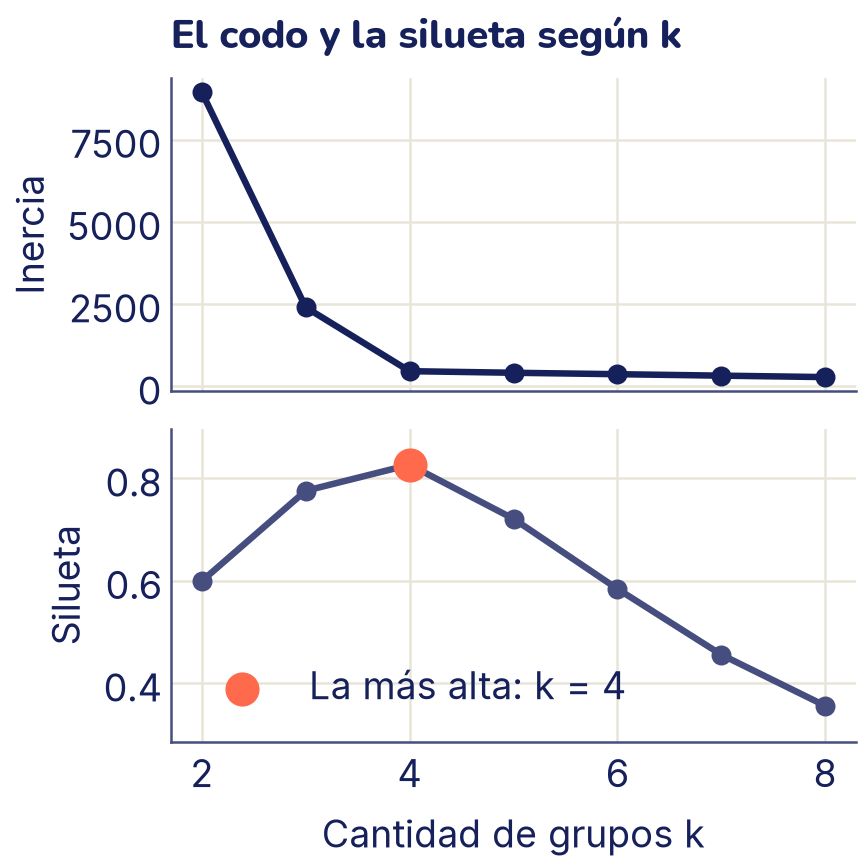

In [ ]:
from sklearn.metrics import silhouette_score

ks = range(2, 9)
inercias, siluetas = [], []
for k in ks:
    m = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X)
    inercias.append(m.inertia_)
    siluetas.append(silhouette_score(X, m.labels_))
    print(f"k = {k}:   inercia {m.inertia_:7.1f}   "
          f"silueta {siluetas[-1]:.3f}")

mejor_k = ks[np.argmax(siluetas)]
fig, (arriba, abajo) = plt.subplots(2, 1, figsize=(4.8, 4.8), sharex=True)
arriba.plot(ks, inercias, marker="o", color="C0")
arriba.set_ylabel("Inercia")
arriba.set_title("El codo y la silueta según k")
abajo.plot(ks, siluetas, marker="o", color="C2")
abajo.scatter([mejor_k], [max(siluetas)], s=160, color="C1", zorder=3,
              label=f"La más alta: k = {mejor_k}")
abajo.set_ylabel("Silueta")
abajo.set_xlabel("Cantidad de grupos k")
# Solo para dibujar: margen para que el punto no toque el borde de arriba
abajo.margins(y=0.15)
abajo.legend()
plt.show()

Los dos métodos coinciden en este caso. La inercia cae de 8942 a 2403 y a 463 entre *k* = 2 y *k* = 4, y después apenas baja (414 con *k* = 5): el codo está en 4. La silueta es máxima en *k* = 4, con 0,826; con 5 grupos baja a 0,721, porque una mancha se parte en dos y sus puntos quedan muy cerca del grupo vecino.

Ninguno de los dos métodos es una ley. Con datos reales el codo suele ser suave y la silueta puede empatar entre dos valores de *k*. Entonces decide también la pregunta: si el dueño de la heladería puede manejar tres promociones y no siete, eso pesa tanto como cualquier número.

## DBSCAN: grupos por densidad

K-means tiene dos límites que viste en la actividad: hay que decirle *k*, y sus grupos son siempre «redondos», porque cada punto va al centroide más cercano. Si los grupos tienen forma de luna o de anillo, falla.

**DBSCAN** piensa distinto: un grupo es una **zona densa**, con muchos puntos apretados, separada de otras zonas densas por zonas casi vacías. Tiene dos parámetros:

- **`eps`**: el radio del vecindario de cada punto (el círculo de la actividad).
- **`min_samples`**: cuántos puntos tiene que haber dentro de ese círculo (contando al propio punto) para que la zona cuente como densa.

Con ellos, cada punto es de uno de tres tipos:

- **Núcleo**: tiene al menos `min_samples` puntos a distancia `eps` o menos. Está en el corazón de un grupo.
- **Borde**: no es núcleo, pero está a distancia `eps` o menos de algún núcleo. Pertenece al grupo de ese núcleo.
- **Ruido**: ni lo uno ni lo otro. DBSCAN no lo pone en ningún grupo y le da la etiqueta −1.

Un grupo se forma encadenando núcleos vecinos: si dos núcleos están a distancia `eps` o menos, van al mismo grupo, y así el grupo puede tomar **cualquier forma**. Además DBSCAN decide solo cuántos grupos hay.

Probemos con `make_moons`, dos medias lunas encajadas, también sintéticas:

In [ ]:
from sklearn.datasets import make_moons
from sklearn.cluster import DBSCAN

X_lunas, y_lunas = make_moons(n_samples=300, noise=0.08, random_state=0)

db = DBSCAN(eps=0.2, min_samples=5).fit(X_lunas)
grupos_db = db.labels_
nucleo = np.zeros(len(X_lunas), dtype=bool)
nucleo[db.core_sample_indices_] = True
ruido = grupos_db == -1
borde = ~nucleo & ~ruido

print("Grupos encontrados:", len(set(grupos_db) - {-1}))
print(f"Núcleo: {nucleo.sum()}   borde: {borde.sum()}   "
      f"ruido: {ruido.sum()}")

Grupos encontrados: 2
Núcleo: 297   borde: 2   ruido: 1


DBSCAN encontró los 2 grupos sin que le dijéramos cuántos. De los 300 puntos, 297 son núcleo, 2 son borde y 1 quedó como ruido: un punto suelto entre las dos lunas, que no tiene suficientes vecinos cerca.

El precio: `eps` hay que elegirlo, y es delicado. Muy chico, casi todo es ruido y aparecen muchos grupos pequeños; muy grande, todo se une en un solo grupo. Como `eps` es una distancia, escalar las columnas otra vez es obligatorio. Y si un grupo es mucho más denso que otro, puede que ningún `eps` sirva para los dos.

## Clustering jerárquico y el dendrograma

El **clustering aglomerativo** construye los grupos de abajo hacia arriba:

1. Al principio, cada punto es su propio grupo.
2. Se unen los dos grupos más cercanos.
3. Se repite hasta que queda un solo grupo con todos.

¿Qué significa «los dos grupos más cercanos»? Depende del **enlace** (*linkage*):

| Enlace | Distancia entre dos grupos | Cómo son los grupos |
|---|---|---|
| `single` (simple) | La de sus dos puntos **más cercanos** | Sigue cadenas y formas largas, pero un puente de puntos puede unir dos grupos |
| `complete` (completo) | La de sus dos puntos **más lejanos** | Compactos y de tamaño parecido |
| `average` (promedio) | El promedio de todas las distancias entre sus puntos | Un término medio |
| `ward` | Cuánto **sube la inercia** si se unen | Redondos, como K-means; es el de scikit-learn por defecto |

Todo el historial de uniones se dibuja como un árbol: el **dendrograma**. Abajo están los puntos; cada unión es una horquilla, y **la altura de la horquilla es la distancia a la que se unieron** esos grupos. Para obtener grupos, se corta el árbol con una línea horizontal: cada rama que la línea cruza es un grupo. Las horquillas muy altas indican grupos bien separados, que conviene no unir.

Con 300 puntos el árbol tiene 300 hojas, demasiadas para leerlas. `truncate_mode="lastp"` dibuja solo las últimas 12 ramas y pone entre paréntesis cuántos puntos tiene cada una.

Forma de Z: (299, 4)
Altura de las 4 últimas uniones: [  9.3  62.3 114.4 162.8]


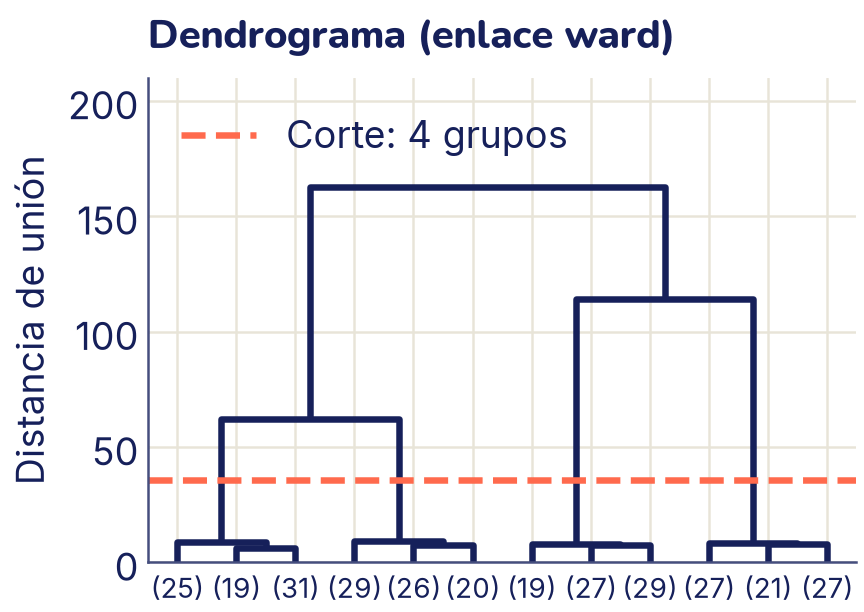

In [ ]:
from scipy.cluster.hierarchy import linkage, dendrogram

# Cada fila de Z es una unión: grupo, grupo, distancia, tamaño
Z = linkage(X, method="ward")
print("Forma de Z:", Z.shape)
print("Altura de las 4 últimas uniones:", Z[-4:, 2].round(1))

# Un corte entre la 4.ª y la 3.ª unión desde arriba deja 4 grupos
corte = (Z[-4, 2] + Z[-3, 2]) / 2
dendrogram(Z, truncate_mode="lastp", p=12, leaf_font_size=11,
           link_color_func=lambda k: "C0")
plt.axhline(corte, color="C1", linestyle="--", label="Corte: 4 grupos")
plt.ylim(0, 210)                      # espacio arriba para la leyenda
plt.ylabel("Distancia de unión")
plt.title("Dendrograma (enlace ward)")
plt.legend(loc="upper left")
plt.show()

El árbol cuenta la historia de las manchas. Abajo, las 12 ramas se unen de a pares o de a tres a muy poca altura (menos de 10): son puntos de una misma mancha. Después hay un salto grande: la siguiente unión ocurre a 62,3, y las dos últimas a 114,4 y 162,8. Ese salto es la señal de que hay **4 grupos** bien separados, y la línea coral corta justo en el espacio vacío. Si cortaras más arriba, entre 62,3 y 114,4, tendrías 3 grupos: dos de las manchas unidas.

En scikit-learn, el aglomerativo es `AgglomerativeClustering`, con la cantidad de grupos (es decir, dónde cortar) y el enlace:

In [ ]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score

grupos_ag = AgglomerativeClustering(n_clusters=4,
                                    linkage="ward").fit_predict(X)
print("Puntos por grupo:", np.bincount(grupos_ag))
print("Acuerdo con K-means:", adjusted_rand_score(grupos_km, grupos_ag))
print("Acuerdo con la verdad:", adjusted_rand_score(y_verdad, grupos_ag))

Puntos por grupo: [75 75 75 75]
Acuerdo con K-means: 1.0
Acuerdo con la verdad: 1.0


Para comparar dos agrupaciones usamos el **índice de Rand ajustado** (`adjusted_rand_score`): mira cada par de puntos y cuenta si las dos agrupaciones coinciden en ponerlos juntos o separados. Vale 1 si las agrupaciones son iguales (sin importar los nombres de los grupos) y cerca de 0 si coinciden tanto como dos agrupaciones al azar. Solo lo podemos usar con `y_verdad` porque los datos son sintéticos; con datos reales sin etiquetas no hay contra qué comparar.

## Clustering espectral: pensar en vecinos

El **clustering espectral** también parte de las cercanías, pero de otra forma. Imagina que cada punto le da la mano a sus 10 vecinos más cercanos: queda una red, un **grafo de vecinos**. Dentro de una luna, cada punto está conectado con muchos de la misma luna; entre las dos lunas hay muy pocas conexiones. El método busca cortar la red en partes **cortando la menor cantidad de conexiones posible**.

La matemática detrás usa los vectores propios (el «espectro») de una matriz que describe el grafo; los vectores propios los vas a ver en el tema 15. La intuición basta: dos puntos van al mismo grupo si se puede ir de uno al otro **saltando entre vecinos**, aunque estén lejos en línea recta. Por eso sigue las formas curvas. Su costo: hay que elegir *k*, y con muchos miles de puntos se vuelve lento.

## Mezclas de gaussianas y densidad: grupos con probabilidad

K-means tiene dos costumbres que a veces molestan. Sus grupos son siempre **redondos**, porque cada punto va al centroide más cercano en línea recta. Y su respuesta es **tajante**: un punto que está justo entre dos manchas va a una de ellas con la misma seguridad que uno que está en el centro. Un **modelo de mezcla de gaussianas** (en inglés, *Gaussian mixture model*) corrige las dos cosas.

La idea: imagina que los datos salieron de varias **campanas** como la normal del tema 5, pero en dos dimensiones. Cada campana tiene un **centro** (como un centroide), una **forma**, que puede ser una elipse estirada y girada en lugar de un círculo, y un **peso**, la fracción de los datos que salió de ella. Agrupar es adivinar esas campanas. Y como cada campana dice qué tan probable es un punto, el modelo puede responder «este punto es 97 % del grupo A y 3 % del B»: una **asignación suave**. Podemos resumirlo así: **K-means con elipses y con probabilidades**.

Probemos con tres manchas **sintéticas** estiradas. Las genera `make_blobs`, y después las estiramos y giramos multiplicando cada punto por una matriz de 2 × 2 con `@`:

In [ ]:
from sklearn.mixture import GaussianMixture

# return_centers=True devuelve también los centros de las manchas
X_m, y_est, centros = make_blobs(n_samples=300, centers=3,
                                 cluster_std=1.15, random_state=170,
                                 return_centers=True)
estirar = np.array([[0.6, -0.6], [-0.4, 0.8]])
# Cada punto (fila) por la matriz: la nube se estira y se gira
X_est = X_m @ estirar

grupos_km3 = KMeans(n_clusters=3, n_init=10,
                    random_state=0).fit_predict(X_est)
gmm = GaussianMixture(n_components=3, n_init=5, random_state=0)
grupos_gmm = gmm.fit_predict(X_est)

print("Acuerdo con la verdad:")
print(f"  K-means: {adjusted_rand_score(y_est, grupos_km3):.2f}")
print(f"  Mezcla:  {adjusted_rand_score(y_est, grupos_gmm):.2f}")
print("Pesos de las campanas:", gmm.weights_.round(2))

Acuerdo con la verdad:
  K-means: 0.45
  Mezcla:  0.99
Pesos de las campanas: [0.33 0.33 0.34]


`n_components` es la cantidad de campanas (el *k* de la mezcla), y `n_init=5` prueba cinco inicios, como en K-means. La mezcla encontró las tres manchas casi exactamente como las generamos (acuerdo 0,99), y K-means no (0,45): sus fronteras son rectas a mitad de camino entre centroides, y las manchas estiradas se pasan de esa mitad, así que les corta las puntas. Los pesos dicen que cada campana explica más o menos un tercio de los puntos.

La asignación suave sale con `predict_proba`: una fila por punto y una columna por campana, y cada fila suma 1.

In [ ]:
prob = gmm.predict_proba(X_est)
print("Probabilidades de los 3 primeros puntos:")
print(prob[:3].round(3))

seguridad = prob.max(axis=1)        # la probabilidad del grupo elegido
dudoso = seguridad.argmin()
print("El punto más dudoso:", X_est[dudoso].round(2),
      "probabilidades", prob[dudoso].round(2))
print("Puntos con menos de 95 % de seguridad:", (seguridad < 0.95).sum())

Probabilidades de los 3 primeros puntos:
[[1. 0. 0.]
 [0. 0. 1.]
 [0. 0. 1.]]
El punto más dudoso: [-1.9   0.35] probabilidades [0.   0.28 0.72]
Puntos con menos de 95 % de seguridad: 3


Los tres primeros puntos pertenecen a su grupo con probabilidad 1 (redondeada a tres decimales), y así casi todos. Solo los que caen donde dos campanas se tocan quedan repartidos: el más dudoso, en (−1,9; 0,35), es 72 % de una campana y 28 % de otra, y apenas 3 de los 300 puntos tienen menos de 95 % de seguridad. K-means habría puesto a esos tres en un grupo con la misma seguridad que a todos los demás. En el dibujo, las **curvas de nivel** marcan dónde la densidad de la mezcla es igual (como las curvas de un mapa de montañas): son elipses alrededor de cada mancha, y no círculos. Los puntos dudosos van en coral.

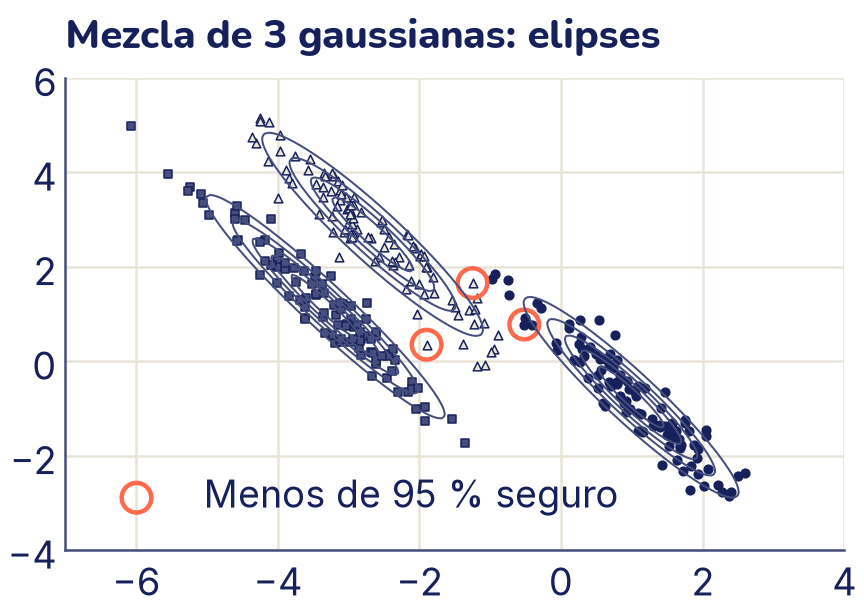

In [ ]:
# Una rejilla de puntos que cubre los datos, para calcular la densidad
A, B = np.meshgrid(np.linspace(-7, 4, 200), np.linspace(-4, 6, 200))
rejilla = np.column_stack([A.ravel(), B.ravel()])
# score_samples da el logaritmo de la densidad; exp lo deshace
densidad = np.exp(gmm.score_samples(rejilla)).reshape(A.shape)

fig, eje = plt.subplots()
eje.contour(A, B, densidad, levels=6, colors="C2", linewidths=0.8)
dibujar_grupos(eje, X_est, grupos_gmm, s=12)
dudosos = X_est[seguridad < 0.95]
eje.scatter(dudosos[:, 0], dudosos[:, 1], s=140, facecolors="none",
            edgecolors="C1", linewidths=1.8, label="Menos de 95 % seguro")
eje.set_title("Mezcla de 3 gaussianas: elipses")
eje.legend(loc="lower left")
plt.show()

### Cómo aprende la mezcla: el algoritmo EM

Nadie le dice a la mezcla dónde están las campanas. Las encuentra con el algoritmo **EM** (de *expectation–maximization*, «esperanza y maximización»), que es el mismo baile de K-means en versión suave:

0. Empezar con unas campanas cualesquiera (scikit-learn las inicia con K-means).
1. **Paso E, asignar con probabilidad**: cada punto calcula, con la fórmula de cada campana, qué tan probable es que haya salido de ella, y reparte su «voto» entre las campanas (es `predict_proba`). Un punto en el centro de una mancha vota casi todo por su campana; uno en la frontera, la mitad y la mitad.
2. **Paso M, mover las campanas**: cada campana se va al **promedio ponderado** de los puntos, donde cada punto cuenta según su voto para ella. Con los mismos votos recalcula su forma (cuánto se estira y hacia dónde) y su peso (la suma de sus votos, dividida entre la cantidad de puntos).
3. Repetir hasta que nada cambie.

Si las campanas fueran todas redondas, del mismo tamaño y los votos fueran todo o nada, EM sería exactamente K-means. Y, como K-means, EM siempre mejora (o deja igual) lo que mide en cada vuelta, pero puede quedarse en una solución que no es la mejor, según dónde empezó: por eso `n_init`. En el ejercicio 9 lo programas tú en una dimensión.

¿Qué mide? La **log-verosimilitud**: qué tan probables son los datos según el modelo. Se calcula la densidad de cada punto según la mezcla, se toma su logaritmo y se promedia. (Igual que en el tema 5, `log` es el logaritmo natural, el ln del colegio; se usa porque convierte el producto de muchas probabilidades chicas en una suma.) Más alta es mejor: quiere decir que las campanas ponen mucha densidad donde hay datos.

### ¿Cuántas campanas? El BIC

Con la log-verosimilitud pasa lo mismo que con la inercia: **siempre mejora al agregar campanas**, porque más campanas se pegan más a los datos. El **BIC** (*Bayesian information criterion*, criterio de información bayesiano) le pone un castigo: cuenta cuántos números tiene que aprender el modelo (centros, formas y pesos) y cobra por cada uno, más cuanto más datos hay.

$$\text{BIC} = - 2 \cdot \text{(log-verosimilitud total)} + \text{(cantidad de parámetros)} \cdot \text{ln} ( n )$$

El primer término baja cuando el modelo se ajusta mejor; el segundo sube con cada campana. Se elige el *k* con el BIC **más bajo**: el que explica bien los datos sin campanas de sobra.

In [ ]:
for k in range(1, 7):
    m = GaussianMixture(n_components=k, n_init=5,
                        random_state=0).fit(X_est)
    print(f"k = {k}:   log-verosimilitud media {m.score(X_est):6.3f}"
          f"   BIC {m.bic(X_est):6.1f}")

k = 1:   log-verosimilitud media -3.615   BIC 2197.5
k = 2:   log-verosimilitud media -3.144   BIC 1949.4
k = 3:   log-verosimilitud media -2.789   BIC 1770.4
k = 4:   log-verosimilitud media -2.772   BIC 1794.4
k = 5:   log-verosimilitud media -2.768   BIC 1826.2
k = 6:   log-verosimilitud media -2.752   BIC 1851.1


La log-verosimilitud media (`score`) sube con cada campana, aunque de *k* = 3 en adelante apenas cambia. El BIC baja hasta *k* = 3 y después sube: la cuarta campana mejora tan poco el ajuste que no paga su castigo. A diferencia del codo, aquí hay un mínimo claro que se puede elegir sin mirar el dibujo.

### Densidad sin campanas fijas: KDE

Una mezcla supone que los datos salen de **pocas** campanas. ¿Y si la forma es cualquiera? La **estimación de densidad por kernel** (KDE, *kernel density estimation*) lleva la idea al extremo: pone una campanita **sobre cada dato** y las promedia. Donde hay muchos datos juntos, las campanitas se apilan y la densidad sube; donde no hay ninguno, queda casi en cero. Es como un histograma suave, sin el problema de dónde empieza cada barra. La campanita se llama **kernel** (núcleo), una palabra que ya viste en el tema 12 con otro uso: allí era una función que mide el parecido entre dos puntos, y aquí es la forma que se pone sobre cada dato.

$$\hat{p} ( x ) = \frac{1}{n} \sum_{i = 1}^{n} \text{normal} ( x ; \; \text{media} \; {x}_{i} , \; \text{desviación} \; h )$$

El único parámetro es el **ancho de banda** *h* (*bandwidth*), la desviación estándar de cada campanita. Probémoslo en una dimensión, con los minutos que tardan 120 estudiantes en llegar al colegio (datos **sintéticos**: 70 vienen a pie y tardan unos 12 minutos; 50 vienen en micro y tardan unos 32). Primero desde cero, con la `densidad_normal` del tema 5, y después con `KernelDensity` de scikit-learn, para ver que dan lo mismo:

In [ ]:
from sklearn.neighbors import KernelDensity

rng = np.random.default_rng(1)
tiempos = np.concatenate([rng.normal(12, 3, 70), rng.normal(32, 6, 50)])

def densidad_normal(x, mu, sigma):
    """La fórmula de la campana, del tema 5."""
    return (np.exp(-(x - mu) ** 2 / (2 * sigma ** 2))
            / (sigma * np.sqrt(2 * np.pi)))

def kde(xs, datos, h):
    """Una campanita de ancho h sobre cada dato, y el promedio."""
    # Tabla (len(xs), len(datos)); el promedio va por filas
    return densidad_normal(xs[:, None], datos[None, :], h).mean(axis=1)

xs = np.array([5.0, 12.0, 22.0, 32.0])
print("Desde cero:  ", kde(xs, tiempos, h=2).round(4))
# scikit-learn quiere una columna, y da el logaritmo de la densidad
modelo_kde = KernelDensity(bandwidth=2).fit(tiempos.reshape(-1, 1))
log_d = modelo_kde.score_samples(xs.reshape(-1, 1))
print("scikit-learn:", np.exp(log_d).round(4))

Desde cero:   [0.0082 0.0754 0.0079 0.0312]
scikit-learn: [0.0082 0.0754 0.0079 0.0312]


La densidad es alta a los 12 minutos (los que caminan) y a los 32 (los del micro), y baja a los 22, entre los dos grupos. ¿Por qué *h* = 2? Por ahora, porque sí. Y el ancho de banda lo cambia todo: con campanitas muy angostas, la curva es una sierra con un pico en cada dato (se **sobreajusta**, como el polinomio de grado alto del tema 7); con campanitas muy anchas, todo se aplana en una sola loma y los dos grupos desaparecen.

Como en el tema 7, el valor se elige con **validación cruzada**: se ajusta la KDE con 4 de los 5 pliegues y se mide la log-verosimilitud (la suma de los logaritmos de la densidad) de los puntos del pliegue que quedó afuera. Si *h* es muy chico, los puntos de validación caen entre los picos, donde la densidad es casi cero, y su logaritmo es muy negativo; si es muy grande, la densidad queda repartida en todas partes y es baja en todos lados. `GridSearchCV` (tema 10) lo hace solo, porque el `score` de `KernelDensity` es justo esa log-verosimilitud. Los datos están ordenados (primero los que caminan), así que hay que mezclarlos al repartir los pliegues: `KFold(5, shuffle=True)`.

In [ ]:
from sklearn.model_selection import GridSearchCV, KFold

anchos = [0.3, 1, 2, 3, 4, 6, 10]
busqueda = GridSearchCV(KernelDensity(), {"bandwidth": anchos},
                        cv=KFold(5, shuffle=True, random_state=0))
busqueda.fit(tiempos.reshape(-1, 1))
for h, s in zip(anchos, busqueda.cv_results_["mean_test_score"]):
    print(f"h = {h:4}:  log-verosimilitud en validación {s:7.1f}")
h_mejor = busqueda.best_params_["bandwidth"]
print("Mejor ancho de banda:", h_mejor)

xs = np.linspace(0, 50, 400)
plt.hist(tiempos, bins=25, density=True, color="C3", label="Histograma")
plt.plot(xs, kde(xs, tiempos, 0.3), color="C2", linewidth=1,
         label="h = 0,3")
plt.plot(xs, kde(xs, tiempos, 10), color="C0", linestyle="--",
         label="h = 10")
plt.plot(xs, kde(xs, tiempos, h_mejor), color="C1", linewidth=2.5,
         label=f"h = {h_mejor} (validación)")
plt.xlabel("Minutos hasta el colegio")
plt.ylabel("Densidad")
plt.title("KDE con tres anchos de banda")
# Solo para dibujar: espacio arriba para la leyenda
plt.ylim(0, 0.19)
plt.legend(fontsize=11, ncol=2)
plt.show()

h =  0.3:  log-verosimilitud en validación  -139.0
h =    1:  log-verosimilitud en validación   -84.6
h =    2:  log-verosimilitud en validación   -81.2
h =    3:  log-verosimilitud en validación   -81.9
h =    4:  log-verosimilitud en validación   -83.5
h =    6:  log-verosimilitud en validación   -87.1
h =   10:  log-verosimilitud en validación   -92.3
Mejor ancho de banda: 2


La validación elige *h* = 2, el que usamos arriba, ahora con una razón: su log-verosimilitud en validación (−81,2) es la más alta, apenas por encima de *h* = 3 (−81,9). Con *h* = 0,3 cae a −139,0, porque los puntos de validación caen entre los picos; con *h* = 10 baja a −92,3, porque la densidad se reparte demasiado. `density=True` escala el histograma para que su área total sea 1, como la de una densidad, y así se puede comparar con las curvas.

La curva coral cuenta lo que el histograma sugiere: dos grupos, uno alto y angosto (los que caminan tardan parecido) y otro más bajo y ancho (el micro varía más). La sierra de *h* = 0,3 inventa picos donde solo hay un dato, y la loma de *h* = 10 borra los dos grupos.

### La densidad baja: detectar anomalías

Una densidad sirve para algo más que agrupar: dice qué tan **normal** es un punto. Si un dato nuevo cae donde la densidad es muy baja, se parece poco a todo lo que vimos antes: es una **anomalía** (un dato atípico), y vale la pena revisarlo. Así se buscan compras con tarjeta raras, fallas de una máquina o errores de medición, sin una lista de ejemplos malos: es el ejercicio 1, punto 5, con otra herramienta.

La receta: calcular la log-densidad de los datos de entrenamiento con `score_samples`, fijar un **umbral** (por ejemplo, el percentil 1: solo el 1 % de los datos de entrenamiento queda por debajo) y marcar como anomalía todo dato nuevo con log-densidad menor. Usemos la mezcla de las manchas estiradas con 30 puntos nuevos de las mismas manchas y 4 puntos raros puestos a mano:

In [ ]:
# Los mismos centros y el mismo estiramiento, con otra semilla
X_m2, _ = make_blobs(n_samples=30, centers=centros, cluster_std=1.15,
                     random_state=1)
nuevos_normales = X_m2 @ estirar
raros = np.array([[-6.0, 1.0], [1.0, 3.5], [-1.0, -2.5], [-1.0, 2.0]])
nuevos = np.vstack([nuevos_normales, raros])

umbral = np.percentile(gmm.score_samples(X_est), 1)
anomalia = gmm.score_samples(nuevos) < umbral
print(f"Umbral de log-densidad: {umbral:.2f}")
print("Marcados entre los 30 normales:", anomalia[:30].sum())
print("Marcados entre los 4 raros:    ", anomalia[30:].sum())

Umbral de log-densidad: -5.75
Marcados entre los 30 normales: 0
Marcados entre los 4 raros:     3


Dibujemos el umbral: la línea discontinua encierra la zona «normal», donde la log-densidad de la mezcla pasa el umbral.

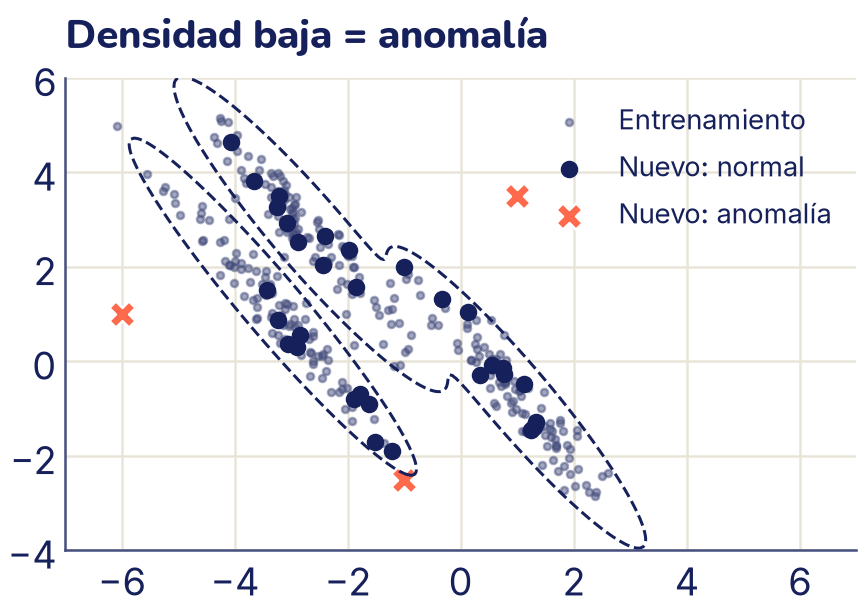

In [ ]:
log_densidad = gmm.score_samples(rejilla).reshape(A.shape)
fig, eje = plt.subplots()
eje.contour(A, B, log_densidad, levels=[umbral], colors="C0",
            linestyles="--", linewidths=1.2)
eje.scatter(X_est[:, 0], X_est[:, 1], s=8, color="C2", alpha=0.5,
            label="Entrenamiento")
eje.scatter(nuevos[~anomalia, 0], nuevos[~anomalia, 1], s=36,
            color="C0", label="Nuevo: normal")
eje.scatter(nuevos[anomalia, 0], nuevos[anomalia, 1], s=110, marker="X",
            color="C1", edgecolors="white", label="Nuevo: anomalía")
eje.set_title("Densidad baja = anomalía")
# Solo para dibujar: espacio a la derecha para la leyenda
eje.set_xlim(-7, 7)
eje.legend(loc="upper right", fontsize=11)
plt.show()

Ninguno de los 30 puntos normales se marcó, y 3 de los 4 raros sí. El que se escapó, (−1, 2), cae donde se tocan dos manchas: ahí hay algunos puntos de entrenamiento, así que la mezcla no lo ve tan raro (su log-densidad, −4,8, queda por encima del umbral de −5,75). Ojo con el umbral: con el percentil 1, se espera que alrededor de 1 de cada 100 datos normales nuevos también quede por debajo y dé una **falsa alarma** (en la práctica suelen ser algo más, como verás en el ejercicio 10). Subir el umbral atrapa más anomalías, pero también da más falsas alarmas; es el mismo equilibrio entre precisión y exhaustividad del tema 9, y lo pruebas en el ejercicio 10.

La misma receta funciona con cualquier modelo de densidad: una mezcla, una KDE o, en una dimensión, la normal del tema 5 (un dato a más de tres desviaciones de la media tiene densidad muy baja: es la regla 68–95–99,7 vista al revés).

### Para profundizar (opcional): KDE en dos dimensiones

Esta parte no hace falta para seguir el tema ni para los ejercicios. La KDE funciona igual en dos dimensiones (o en diez): una campanita redonda sobre cada punto. Donde la mezcla de gaussianas necesita que los datos tengan forma de elipses, la KDE sigue cualquier forma. Comparemos las dos con las lunas, que ninguna elipse describe bien. Para medir cuál describe mejor las lunas, usamos 300 puntos **nuevos** de las mismas lunas, que ninguno de los dos modelos vio, y promediamos su log-densidad: como en la validación, más alta es mejor.

Ancho de banda elegido: 0.1
Mezcla de 2  log-densidad media en datos nuevos: -1.74
KDE          log-densidad media en datos nuevos: -0.95


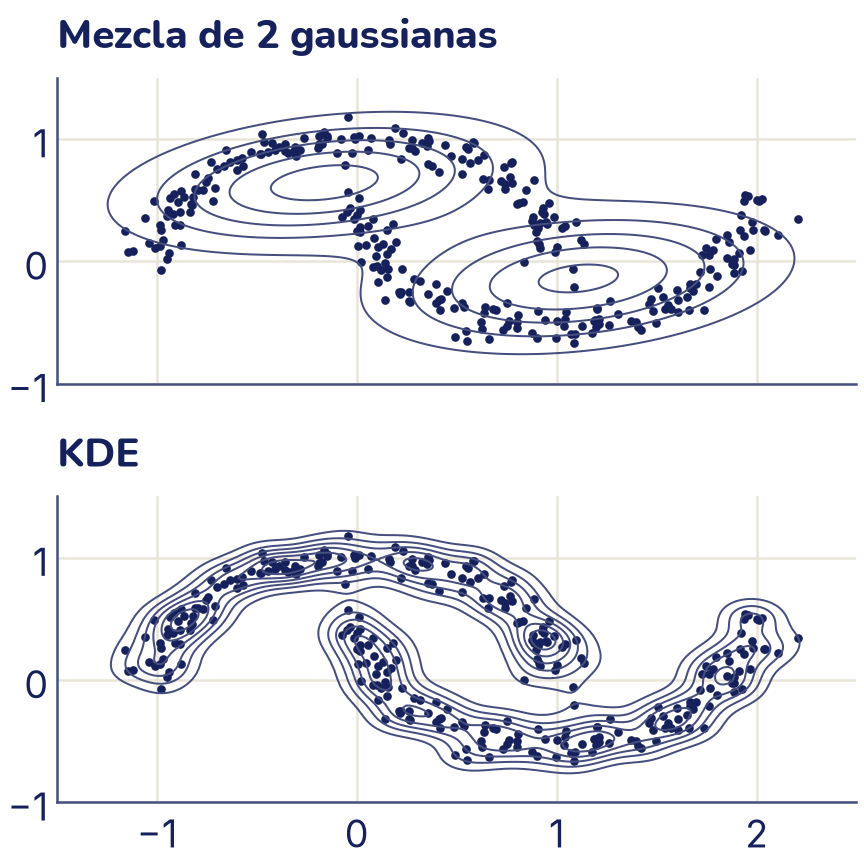

In [ ]:
busqueda_2d = GridSearchCV(KernelDensity(),
                           {"bandwidth": [0.03, 0.05, 0.1, 0.2, 0.4]},
                           cv=KFold(5, shuffle=True, random_state=0))
kde_lunas = busqueda_2d.fit(X_lunas).best_estimator_
gmm_lunas = GaussianMixture(n_components=2, random_state=0).fit(X_lunas)
print("Ancho de banda elegido:", kde_lunas.bandwidth)

X_lunas_nuevas, _ = make_moons(n_samples=300, noise=0.08, random_state=1)
for nombre, m in [("Mezcla de 2", gmm_lunas), ("KDE", kde_lunas)]:
    media = m.score_samples(X_lunas_nuevas).mean()
    print(f"{nombre:12s} log-densidad media en datos nuevos: {media:.2f}")

A2, B2 = np.meshgrid(np.linspace(-1.5, 2.5, 200),
                     np.linspace(-1, 1.5, 200))
rejilla2 = np.column_stack([A2.ravel(), B2.ravel()])
fig, ejes = plt.subplots(2, 1, figsize=(4.8, 4.8), sharex=True)
for eje, (nombre, m) in zip(ejes, [("Mezcla de 2 gaussianas", gmm_lunas),
                                   ("KDE", kde_lunas)]):
    dens = np.exp(m.score_samples(rejilla2)).reshape(A2.shape)
    eje.contour(A2, B2, dens, levels=6, colors="C2", linewidths=0.8)
    eje.scatter(X_lunas[:, 0], X_lunas[:, 1], s=6, color="C0")
    eje.set_title(nombre)
plt.show()

Las elipses de la mezcla cubren zonas vacías y dejan afuera las puntas de las lunas; las curvas de la KDE las abrazan. Los números lo confirman con datos que ningún modelo vio: la log-densidad media de la KDE (−0,95) es más alta que la de la mezcla (−1,74). La KDE tiene sus costos: guarda **todos** los datos y, para cada punto nuevo, mira la distancia a todos ellos (lento con muchos datos); usa el mismo ancho en todas partes; y, como todo lo que usa distancias, necesita las columnas escaladas. Con muchas columnas necesita además muchísimos datos para llenar el espacio. Por eso, cuando los datos sí se parecen a unas pocas campanas, la mezcla es la opción más económica.

## Los cinco métodos sobre las lunas

Ahora sí, comparemos los cinco con las mismas lunas. El sexto panel muestra las lunas reales, para comparar:

K-means            acuerdo con las lunas: 0.23
DBSCAN             acuerdo con las lunas: 0.99
Jerárquico simple  acuerdo con las lunas: 1.00
Espectral          acuerdo con las lunas: 0.97
Mezcla gaussiana   acuerdo con las lunas: 0.47


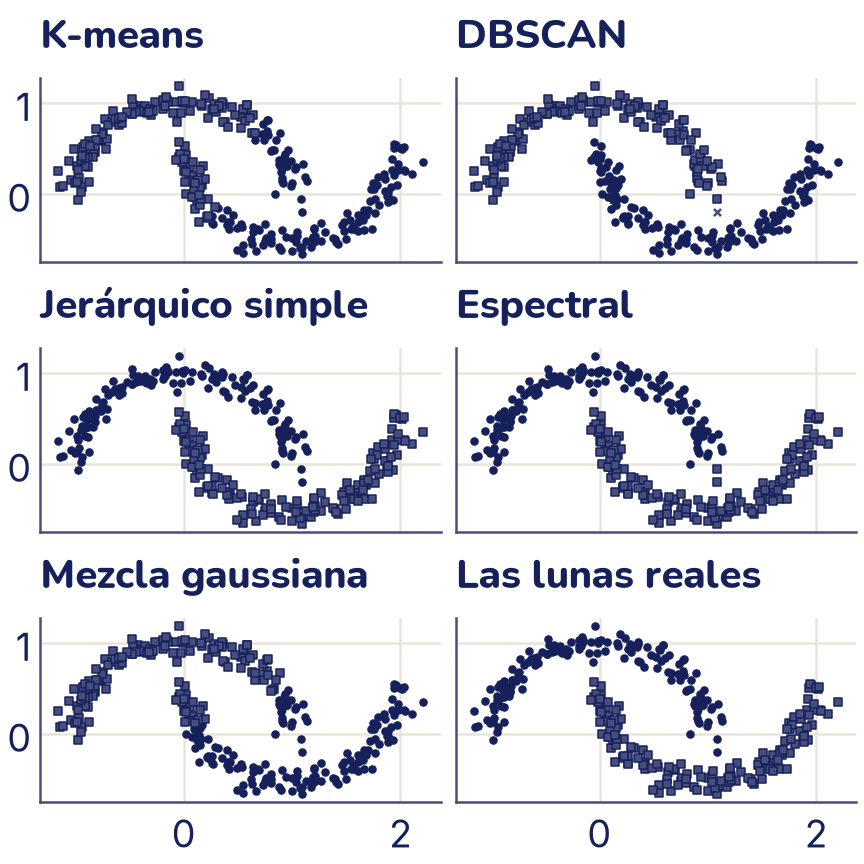

In [ ]:
from sklearn.cluster import SpectralClustering

metodos = {
    "K-means": KMeans(n_clusters=2, n_init=10, random_state=0),
    "DBSCAN": DBSCAN(eps=0.2, min_samples=5),
    "Jerárquico simple": AgglomerativeClustering(n_clusters=2,
                                                 linkage="single"),
    "Espectral": SpectralClustering(n_clusters=2,
                                    affinity="nearest_neighbors",
                                    random_state=0),
    "Mezcla gaussiana": GaussianMixture(n_components=2, random_state=0),
}

fig, ejes = plt.subplots(3, 2, figsize=(4.8, 4.8),
                         sharex=True, sharey=True)
for eje, (nombre, metodo) in zip(ejes.flat, metodos.items()):
    grupos = metodo.fit_predict(X_lunas)
    acuerdo = adjusted_rand_score(y_lunas, grupos)
    print(f"{nombre:18s} acuerdo con las lunas: {acuerdo:.2f}")
    dibujar_grupos(eje, X_lunas, grupos, s=8)
    eje.set_title(nombre)
dibujar_grupos(ejes[2, 1], X_lunas, y_lunas, s=8)
ejes[2, 1].set_title("Las lunas reales")
plt.show()

K-means obtiene un acuerdo de solo 0,23: como asigna cada punto al centroide más cercano, la frontera entre sus dos grupos es una recta, y corta la punta de cada luna. DBSCAN, el jerárquico y el espectral siguen la forma. DBSCAN acierta en todo menos en el punto que marca como ruido (0,99); el jerárquico con enlace simple las separa perfecto (1,00), porque encadena vecinos uno tras otro, y el espectral se equivoca solo en unos pocos puntos de las puntas (0,97). La mezcla gaussiana (0,47) mejora un poco a K-means, porque sus elipses pueden inclinarse, pero tampoco sigue la curva: cada campana es una elipse, y una luna no lo es. Su fuerte son las manchas estiradas y las probabilidades, no las formas curvas. Cuidado con sacar una regla de una sola figura: con más ruido entre las lunas, el enlace simple une todo por un puente de puntos y DBSCAN necesita otro `eps`.

## ¿Cuál usar?

| Método | Hay que darle | Grupos que encuentra | Ruido | Cuándo usarlo |
|---|---|---|---|---|
| K-means | *k* | Redondos y de tamaño parecido | No: todo punto va a un grupo | Primera prueba; muchos datos; comprimir (como los colores de una foto) |
| DBSCAN | `eps` y `min_samples` | De cualquier forma, si la densidad es parecida | Sí: lo marca como −1 | Formas raras, datos con puntos sueltos, cuando no sabes *k* |
| Jerárquico | *k* (o la altura de corte) y el enlace | Depende del enlace | No | Pocos datos (hasta algunos miles); cuando quieres ver la jerarquía en un dendrograma |
| Espectral | *k* | Formas curvas conectadas | No | Formas entrelazadas con pocos datos |
| Mezcla de gaussianas | *k* (o el BIC para elegirlo) | Elipses de cualquier tamaño e inclinación | No, pero la densidad baja señala los puntos raros | Cuando quieres la probabilidad de cada grupo; manchas estiradas; detectar anomalías |

Y para todos: **escala las columnas antes**, **mira el resultado** (dibuja los grupos o describe cada uno con promedios) y recuerda que los grupos son una herramienta para entender los datos, no una verdad escondida. Dos métodos razonables pueden dar dos agrupaciones distintas, y las dos pueden ser útiles.

## Comprimir una foto con K-means

En el tema 3 viste que una foto es un arreglo de (alto, ancho, 3). Si ponemos cada píxel como una fila de tres números (rojo, verde, azul), una foto es una nube de puntos en tres dimensiones, y **agrupar los píxeles es agrupar colores**. Si reemplazamos cada píxel por el centroide de su grupo, la foto queda pintada con solo *k* colores. Es lo que hace un formato como GIF, que usa como máximo 256 colores.

La foto tiene 273 280 píxeles. Para que sea rápido, entrenamos K-means con 2000 píxeles al azar y después usamos `predict` para asignar todos los píxeles al color más cercano.

Píxeles: (273280, 3)
Colores distintos en la foto: 96615


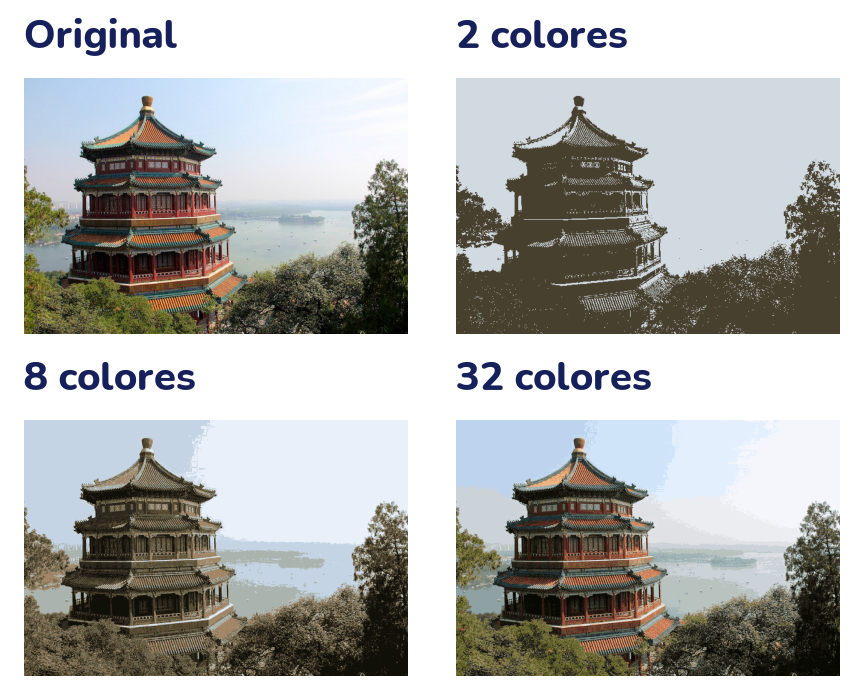

In [ ]:
from sklearn.datasets import load_sample_image

foto = load_sample_image("china.jpg")
# Una fila por píxel, con sus tres canales entre 0 y 1
pixeles = foto.reshape(-1, 3) / 255
print("Píxeles:", pixeles.shape)
print("Colores distintos en la foto:", len(np.unique(pixeles, axis=0)))

rng = np.random.default_rng(0)
muestra = pixeles[rng.choice(len(pixeles), size=2000, replace=False)]

# Solo para dibujar: las fotos son apaisadas, así que la figura es más baja
fig, ejes = plt.subplots(2, 2, figsize=(4.8, 3.8))
ejes[0, 0].imshow(foto)
ejes[0, 0].set_title("Original")
for eje, k in zip(ejes.flat[1:], [2, 8, 32]):
    colores = KMeans(n_clusters=k, n_init=4, random_state=0).fit(muestra)
    # Cada píxel se reemplaza por el centroide (el color) de su grupo
    grupo = colores.predict(pixeles)
    reducida = colores.cluster_centers_[grupo].reshape(foto.shape)
    eje.imshow(reducida)
    eje.set_title(f"{k} colores")
for eje in ejes.flat:
    eje.axis("off")
plt.show()

La foto original tiene 96 615 colores distintos. Con 2 colores solo queda una silueta clara y una oscura. Con 8 ya se reconocen el cielo, el agua y los árboles, pero el rojo del techo desapareció: ningún centroide cayó en el rojo, porque son pocos píxeles comparados con el cielo y los árboles. Con 32 colores, el rojo vuelve y la foto se parece mucho a la original. Guardar la foto así ocupa mucho menos: en lugar de tres números de 0 a 255 por píxel, basta con un número de 0 a 31 por píxel (con 5 cifras binarias, o bits, se escriben 2⁵ = 32 valores), más la tabla de 32 colores.

## Lo que aprendiste y lo que sigue

- El **aprendizaje no supervisado** busca estructura en datos sin etiquetas. Agrupar es encontrar puntos cercanos entre sí y lejos del resto, y la cercanía depende de la **escala** de las columnas.
- **K-means** repite «asignar al centroide más cercano, mover el centroide al promedio» y baja la **inercia** hasta un mínimo, que puede ser **local**. **k-means++** y `n_init` lo evitan casi siempre.
- El **codo** de la inercia y la **silueta** más alta ayudan a elegir *k*, pero no lo deciden solos.
- **DBSCAN** encuentra grupos de cualquier forma como zonas densas, con `eps` y `min_samples`, y marca el **ruido**.
- El **aglomerativo** une grupos de abajo hacia arriba según un **enlace**; el **dendrograma** muestra todas las uniones y se corta para obtener grupos.
- El **espectral** agrupa saltando entre vecinos y separa formas que K-means no puede.
- Una **mezcla de gaussianas** es K-means con elipses y **asignación suave**: el algoritmo **EM** alterna repartir cada punto con probabilidades y mover las campanas, y el **BIC** más bajo ayuda a elegir *k*. La **KDE** pone una campanita sobre cada dato; su **ancho de banda** se elige con validación cruzada. Un dato donde la densidad es muy baja es una **anomalía**.

En el tema 15 vas a ver otra forma de aprender sin etiquetas: **reducir dimensiones**, para dibujar en dos dimensiones datos que tienen muchas, y así poder mirar los grupos.

# Ejercicios

## Antes de empezar

Varios ejercicios usan las variables y funciones de la teoría: `X` (los 300 puntos de las manchas), `y_verdad`, `kmeans`, `inercia`, `dibujar_grupos`, `X_lunas`, `y_lunas`, `Z` (las uniones del dendrograma) y, de la sección de mezclas, `centros`, `estirar`, `X_est`, `gmm`, `raros`, `tiempos` y `densidad_normal`, además de lo importado allá (`KMeans`, `DBSCAN`, `AgglomerativeClustering`, `GaussianMixture`, `adjusted_rand_score`, `silhouette_score`, `make_blobs`, `make_moons`). En este cuaderno, ejecuta las celdas de la teoría y trabaja en los ejercicios, que vienen debajo. Intenta cada ejercicio antes de abrir la respuesta.

## Ejercicios

### 1. ¿Con etiquetas o sin ellas?

Para cada situación, di si es aprendizaje supervisado o no supervisado, y por qué.

1. Predecir el precio de una casa a partir de su tamaño, con una tabla de casas ya vendidas.
2. Separar en grupos a los usuarios de una biblioteca según los libros que piden, sin saber de antemano qué grupos hay.
3. Decidir si un correo es basura, con miles de correos que alguien ya marcó como basura o no.
4. Reducir una foto a 16 colores.
5. Encontrar compras con tarjeta muy distintas de todas las demás, sin una lista de fraudes conocidos.

<details>
<summary>Respuesta</summary>

1. **Supervisado**: cada casa vendida trae la respuesta (el precio). Es una regresión, como en el tema 6.
2. **No supervisado**: no hay grupos dados; hay que descubrirlos. Es clustering.
3. **Supervisado**: los correos marcados son las etiquetas. Es una clasificación.
4. **No supervisado**: nadie dice cuáles son los 16 colores; K-means los encuentra agrupando los píxeles.
5. **No supervisado**: se buscan puntos raros sin etiquetas. DBSCAN sirve para esto: lo que marca como ruido (−1) son candidatos a revisar.

</details>

### 2. K-means a mano en una recta

Seis puntos en una recta: 1, 2, 3, 8, 9 y 13. Haz K-means con *k* = 2 empezando con los centroides en 1 y en 2. En cada vuelta, escribe qué puntos van a cada grupo y a dónde se mueven los centroides, hasta que no cambien. Calcula la inercia final. Después compruébalo con la función `kmeans` de la teoría (los puntos tienen que ir como una columna, con forma (6, 1)).

<details>
<summary>Respuesta</summary>

- **Vuelta 1.** Con centroides 1 y 2, el 1 va al primero y todos los demás (2, 3, 8, 9, 13) al segundo, porque están más cerca del 2. El primer centroide queda en 1 y el segundo se mueve al promedio (2 + 3 + 8 + 9 + 13) / 5 = **7**.
- **Vuelta 2.** Con centroides 1 y 7: el 2 está a 1 del primero y a 5 del segundo, y el 3 está a 2 y a 4, así que los dos se pasan al primer grupo. Grupos: 1, 2, 3 y 8, 9, 13. Centroides: **2** y **10**.
- **Vuelta 3.** Con centroides 2 y 10 nadie cambia de grupo, y los centroides se quedan quietos. Terminó.

Inercia = (1 − 2)² + (2 − 2)² + (3 − 2)² + (8 − 10)² + (9 − 10)² + (13 − 10)² = 1 + 0 + 1 + 4 + 1 + 9 = **16**.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
recta = np.array([1, 2, 3, 8, 9, 13]).reshape(-1, 1)
g_recta, c_recta, h = kmeans(recta, np.array([[1.0], [2.0]]))
print("Grupos:", g_recta)
print("Centroides de cada vuelta:", [ci.ravel().tolist() for ci in h])
print("Inercia:", inercia(recta, g_recta, c_recta))

### 3. Una mala inicialización

Con los 300 puntos de la teoría, elige **a mano** cuatro centroides iniciales que dejen a K-means en un mal mínimo local. Pásalos a tu función `kmeans` y compara la inercia final con 462,8. Después dale los mismos centroides a scikit-learn con `KMeans(n_clusters=4, init=tus_centroides, n_init=1)`. ¿Llega al mismo lugar? ¿Qué cambia si en lugar de eso usas `KMeans(n_clusters=4, n_init=10, random_state=0)`?

Pista: mira la figura de los datos. ¿Qué pasa si dos centroides empiezan en la misma mancha?

<details>
<summary>Respuesta</summary>

Una forma: dos centroides en la mancha de la derecha, uno en la de abajo y uno entre las dos manchas de arriba.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
malos = np.array([[9.0, 0.0], [10.0, 1.0], [0.0, -9.0], [-5.0, 5.0]])
g, c, h = kmeans(X, malos)
print(f"Nuestra función:  inercia {inercia(X, g, c):.1f}   "
      f"tamaños {np.bincount(g)}")

mismo_inicio = KMeans(n_clusters=4, init=malos, n_init=1).fit(X)
print(f"scikit-learn, mismo inicio:  inercia {mismo_inicio.inertia_:.1f}")

varios = KMeans(n_clusters=4, n_init=10, random_state=0).fit(X)
print(f"scikit-learn, k-means++ y n_init=10:  "
      f"inercia {varios.inertia_:.1f}")

<details>
<summary>Respuesta (sigue)</summary>

Con esos centroides, K-means termina con una inercia de 2358,0, unas cinco veces más que 462,8. Los tamaños lo explican: el grupo de 150 puntos son las **dos manchas de arriba unidas** (el centroide que pusimos entre ellas se las quedó a las dos), y la mancha de la derecha quedó **partida** en dos grupos de 33 y 42 puntos, porque tenía dos centroides. scikit-learn, con el mismo inicio y una sola corrida, llega exactamente al mismo mal mínimo: el algoritmo es el mismo. Con k-means++ y 10 inicios, en cambio, llega a 462,8, la buena agrupación.

</details>

### 4. La silueta de un punto, a mano

Con el resultado del ejercicio 2 (grupos 1, 2, 3 y 8, 9, 13), calcula a mano la silueta del punto 3: su *a*, su *b* y su *s*. ¿Por qué es menor que la del punto 1? Compruébalo con `silhouette_samples`, que da la silueta de cada punto.

<details>
<summary>Respuesta</summary>

Para el punto 3:

- *a* = distancia promedio a los otros puntos de su grupo = (|3 − 1| + |3 − 2|) / 2 = (2 + 1) / 2 = **1,5**.
- *b* = distancia promedio al otro grupo = (|3 − 8| + |3 − 9| + |3 − 13|) / 3 = (5 + 6 + 10) / 3 = **7**.
- *s* = (*b* − *a*) / máx(*a*, *b*) = (7 − 1,5) / 7 ≈ **0,786**.

El punto 1 está en la punta, todavía más lejos del otro grupo (*b* = (7 + 8 + 12) / 3 = 9) y con la misma *a* = 1,5, así que su silueta es más alta. El 3 es el punto del primer grupo más cercano al segundo: el que está más «en la frontera».

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
from sklearn.metrics import silhouette_samples

sil = silhouette_samples(recta, g_recta)
for x, s in zip(recta.ravel(), sil):
    print(f"punto {x:2d}:  silueta {s:.3f}")

### 5. La escala manda

Una librería tiene datos **sintéticos** de 200 clientes: la edad y el gasto mensual en bolivianos. La mitad son estudiantes de colegio (unos 17 años) y la otra mitad, adultos (unos 45). El gasto no depende del grupo. Agrupa con K-means (*k* = 2) sin escalar y escalando con `StandardScaler` dentro de un `Pipeline` (tema 10). ¿Cuál encuentra a estudiantes y adultos? ¿Por qué?

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

rng = np.random.default_rng(0)
edad = np.concatenate([rng.normal(17, 2, 100), rng.normal(45, 6, 100)])
gasto = rng.normal(400, 120, 200)          # bolivianos al mes
clientes = np.column_stack([edad, gasto])
tipo = np.repeat([0, 1], 100)              # 0: estudiante, 1: adulto
print(clientes[:3].round(1))

[[ 17.3 320.4]
 [ 16.7 326.4]
 [ 18.3 207.4]]


In [ ]:
# @title Respuesta: código (doble clic para verlo)
sin_escalar = KMeans(n_clusters=2, n_init=10, random_state=0)
con_escala = make_pipeline(StandardScaler(),
                           KMeans(n_clusters=2, n_init=10, random_state=0))

for nombre, modelo in [("Sin escalar", sin_escalar),
                       ("Escalando  ", con_escala)]:
    g = modelo.fit_predict(clientes)
    medias = [clientes[g == j].mean(axis=0).round(0) for j in (0, 1)]
    print(f"{nombre}: acuerdo {adjusted_rand_score(tipo, g):.2f}  "
          f"medias (edad, gasto) {medias[0]} {medias[1]}")

<details>
<summary>Respuesta</summary>

Sin escalar, el acuerdo con los tipos reales es 0,01: como al azar. Los dos grupos tienen casi la misma edad promedio (32 y 30 años) y se diferencian en el gasto (500 y 304 Bs): K-means partió a los clientes en «gastan más» y «gastan menos», que no es ninguna estructura real de estos datos. La razón es la escala: entre dos clientes, el gasto puede diferir en cientos de bolivianos y la edad, en unas decenas de años, así que en la distancia euclidiana el gasto pesa mucho más. Escalando, cada columna pesa lo mismo y el acuerdo es 1,00: un grupo de 17 años de promedio y otro de 45, con un gasto parecido.

</details>

### 6. Mover eps

Con las lunas de la teoría (`X_lunas`), corre DBSCAN con `min_samples=5` y `eps` igual a 0,05; 0,1; 0,2 y 0,5. Para cada uno, cuenta los grupos y los puntos de ruido. Antes de correrlo, predice qué va a pasar en los extremos.

In [ ]:
# @title Respuesta: código (doble clic para verlo)
for eps in [0.05, 0.1, 0.2, 0.5]:
    g = DBSCAN(eps=eps, min_samples=5).fit_predict(X_lunas)
    print(f"eps = {eps:4}:  grupos {len(set(g) - {-1}):2d}   "
          f"ruido {(g == -1).sum():3d}   "
          f"acuerdo {adjusted_rand_score(y_lunas, g):.2f}")

<details>
<summary>Respuesta</summary>

- Con `eps` = 0,05 el círculo es tan chico que casi nadie tiene 5 vecinos: 278 de los 300 puntos son ruido.
- Con 0,1 aparecen 14 grupitos sueltos y 38 puntos de ruido: las lunas se rompen en pedazos.
- Con 0,2 salen las dos lunas y un solo punto de ruido.
- Con 0,5 el círculo es tan grande que alcanza a la otra luna: todo queda en un solo grupo.

`eps` controla qué tan cerca tienen que estar los puntos para encadenarse. Hay una franja de valores que funciona; fuera de ella, o todo es ruido o todo se une.

</details>

### 7. Elegir el algoritmo

Cuatro conjuntos sintéticos de 300 puntos, todos estandarizados:

- **manchas**: tres manchas redondas;
- **lunas**: las dos lunas de la teoría;
- **anillos**: un anillo chico dentro de uno grande;
- **densidades**: una mancha muy apretada al lado de otra muy dispersa.

Antes de correr el código, dibuja (o imagina) cada conjunto y predice qué método funciona en cada uno: K-means, DBSCAN (`eps=0.3`) o el jerárquico con enlace simple. Después corre el código y compara con tu predicción.

In [ ]:
from sklearn.datasets import make_circles

formas = {
    "manchas": make_blobs(n_samples=300, centers=3, random_state=1),
    "lunas": make_moons(n_samples=300, noise=0.08, random_state=0),
    "anillos": make_circles(n_samples=300, factor=0.4, noise=0.05,
                            random_state=0),
    "densidades": make_blobs(n_samples=300, centers=[[0, 0], [6, 0]],
                             cluster_std=[0.4, 2.0], random_state=0),
}

print("              K-means  DBSCAN  Simple")
for nombre, (datos, verdad) in formas.items():
    datos = StandardScaler().fit_transform(datos)
    k = len(np.unique(verdad))
    metodos = [KMeans(n_clusters=k, n_init=10, random_state=0),
               DBSCAN(eps=0.3),
               AgglomerativeClustering(n_clusters=k, linkage="single")]
    acuerdos = [adjusted_rand_score(verdad, m.fit_predict(datos))
                for m in metodos]
    print(f"{nombre:12s}" + "".join(f"{a:8.2f}" for a in acuerdos))

              K-means  DBSCAN  Simple
manchas         0.98    0.57    0.57
lunas           0.43    0.99    1.00
anillos        -0.00    0.86    1.00
densidades      0.73    0.70    0.00


<details>
<summary>Respuesta</summary>

- **manchas**: K-means acierta (0,98), porque los grupos son redondos. DBSCAN y el enlace simple se quedan en 0,57: dos de las manchas se tocan, y los dos métodos las encadenan en un solo grupo.
- **lunas**: K-means falla (0,43); DBSCAN (0,99) y el enlace simple (1,00) siguen la forma.
- **anillos**: K-means no tiene ninguna posibilidad (0,00), porque el centro de los dos anillos es el mismo. El enlace simple separa los anillos perfecto (1,00) y DBSCAN casi (0,86).
- **densidades**: ninguno es perfecto. K-means (0,73) le pasa 22 puntos de la mancha dispersa a la apretada: su frontera queda a mitad de camino entre los dos centroides, y la mancha dispersa se extiende más allá de esa mitad. DBSCAN (0,70) no tiene un `eps` que sirva para las dos densidades: con 0,3 agrupa bien la mancha apretada, pero deja 58 puntos de la dispersa como ruido. El enlace simple (0,00) une las dos manchas en un grupo y deja como «segundo grupo» a 4 puntos sueltos.

La lección: no hay un método que gane siempre. Mira la forma de los datos (o pruébalos todos y mira los grupos) antes de quedarte con uno.

</details>

### 8. Leer el dendrograma

Mira el dendrograma de la teoría. Las cuatro últimas uniones ocurren a las alturas 9,3; 62,3; 114,4 y 162,8.

1. ¿Cuántos grupos quedan si cortas a la altura 80? ¿Y a 130? ¿Y a 5? (Este último no se puede contar a mano con las cuatro alturas: compruébalo con el código de abajo.)
2. ¿Qué altura de corte elegirías y por qué?

Compruébalo con `fcluster(Z, t=altura, criterion="distance")` de `scipy.cluster.hierarchy`, que corta el árbol a esa altura y devuelve el grupo de cada punto.

<details>
<summary>Respuesta</summary>

1. Una línea a la altura *h* deja separados los grupos que se unen **por encima** de *h*. A 80, las uniones de 114,4 y 162,8 quedan arriba: se deshacen dos uniones y quedan **3 grupos**. A 130, solo la de 162,8 queda arriba: **2 grupos**. A 5 hay que cortar también uniones dentro de cada mancha, que no están en la lista de alturas: `fcluster` dice que quedan **14 grupos**.
2. Un corte donde hay un **salto grande** entre una unión y la siguiente: entre 9,3 y 62,3, como la línea coral. Ahí se separan grupos que están lejos entre sí, sin partir ninguna mancha.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
from scipy.cluster.hierarchy import fcluster

for altura in [5, 35, 80, 130]:
    g = fcluster(Z, t=altura, criterion="distance")
    print(f"Corte a {altura:3d}:  {len(np.unique(g)):3d} grupos")

### 9. EM a mano en una recta

Programa el algoritmo EM para una mezcla de **dos** campanas en una dimensión y úsalo con los `tiempos` de la teoría (los minutos hasta el colegio). Empieza con medias 5 y 40, desviaciones 5 y 5, y pesos 0,5 y 0,5, y da 50 vueltas. En cada vuelta:

- **Paso E**: para cada punto, calcula peso × densidad de cada campana (con `densidad_normal`) y divide entre la suma de las dos: ese es su voto para cada campana.
- **Paso M**: cada media es el promedio de los puntos ponderado por los votos; cada desviación, la raíz del promedio ponderado de (punto − media)²; cada peso, la suma de los votos dividida entre la cantidad de puntos.

¿Recuperas los valores con los que se generaron los datos (12 y 32 minutos, desviaciones 3 y 6, y 70 de 120 a pie)? Compara con `GaussianMixture(n_components=2)`.

In [ ]:
# @title Respuesta: código (doble clic para verlo)
def em_1d(x, mu, sigma, peso, vueltas=50):
    """EM para una mezcla de campanas en una dimensión."""
    for _ in range(vueltas):
        # Paso E: peso × densidad de cada punto en cada campana, (n, 2)
        d = peso * densidad_normal(x[:, None], mu, sigma)
        # keepdims=True deja la suma con forma (n, 1), para dividir
        voto = d / d.sum(axis=1, keepdims=True)
        # Paso M: promedios ponderados por los votos de cada campana
        total = voto.sum(axis=0)
        mu = (voto * x[:, None]).sum(axis=0) / total
        varianza = (voto * (x[:, None] - mu) ** 2).sum(axis=0) / total
        sigma = np.sqrt(varianza)
        peso = total / len(x)
    return mu, sigma, peso

mu, sigma, peso = em_1d(tiempos, np.array([5.0, 40.0]),
                        np.array([5.0, 5.0]), np.array([0.5, 0.5]))
print("Nuestro EM:   medias", mu.round(2), " desviaciones",
      sigma.round(2), " pesos", peso.round(2))

ref = GaussianMixture(n_components=2, random_state=0)
ref.fit(tiempos.reshape(-1, 1))
orden = np.argsort(ref.means_.ravel())      # de menor a mayor media
print("scikit-learn: medias", ref.means_.ravel()[orden].round(2),
      " desviaciones", np.sqrt(ref.covariances_.ravel()[orden]).round(2),
      " pesos", ref.weights_[orden].round(2))

<details>
<summary>Respuesta</summary>

Las dos versiones casi coinciden: difieren a lo más en el segundo decimal, porque scikit-learn se detiene cuando los cambios son muy chicos y empieza desde K-means. Y se acercan a los valores reales: medias de 11,83 y 32,06 minutos (reales: 12 y 32), pesos de 0,59 y 0,41 (reales: 70/120 ≈ 0,58 y 0,42). Las desviaciones, 2,61 y 4,85, salen algo menores que 3 y 6: con solo 70 y 50 puntos, la muestra que tocó estaba un poco más apretada que la regla con la que se generó. EM no ve la regla, solo los datos.

Fíjate en la estructura: el paso E es el «asignar» de K-means con votos en lugar de una sola elección, y el paso M es el «mover» con promedios ponderados.

</details>

### 10. ¿Dónde poner el umbral?

En la teoría marcamos como anomalía todo dato con log-densidad menor que el percentil 1 de los datos de entrenamiento. Con 300 puntos normales **nuevos** de las mismas manchas y los 4 puntos `raros` de la teoría, prueba los percentiles 0,5; 1; 5 y 10. Para cada uno, cuenta las **falsas alarmas** (normales marcados) y los raros atrapados. ¿Qué percentil elegirías si revisar una alarma cuesta poco? ¿Y si cuesta mucho?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
X_m3, _ = make_blobs(n_samples=300, centers=centros, cluster_std=1.15,
                     random_state=2)
normales = X_m3 @ estirar
log_entrenamiento = gmm.score_samples(X_est)
for pct in [0.5, 1, 5, 10]:
    u = np.percentile(log_entrenamiento, pct)
    falsas = (gmm.score_samples(normales) < u).sum()
    atrapados = (gmm.score_samples(raros) < u).sum()
    print(f"percentil {pct:4}:  umbral {u:6.2f}   falsas alarmas "
          f"{falsas:2d} de 300   raros atrapados {atrapados} de 4")

<details>
<summary>Respuesta</summary>

- Con el percentil 0,5 o 1, el umbral es bajo: se escapa el raro de (−1, 2), que está entre dos manchas, y hay 6 o 9 falsas alarmas entre 300.
- Con el percentil 5 se atrapan los 4 raros, a cambio de 21 falsas alarmas; con el 10, 36.

Subir el umbral atrapa más anomalías y da más falsas alarmas: es el equilibrio entre exhaustividad y precisión del tema 9. Si revisar una alarma cuesta poco (mirar una compra dudosa), conviene un percentil alto, como 5; si cuesta mucho (parar una máquina), uno bajo, como 0,5 o 1.

Otro detalle: con el percentil 1 se esperaría 1 % de falsas alarmas, unas 3 de 300, y hubo 9. La mezcla se ajustó a los datos de entrenamiento, así que esos puntos le parecen un poco más «normales» que los nuevos: es el sobreajuste del tema 7. Por eso el umbral conviene revisarlo con datos que el modelo no vio.

</details>

## Mini-proyecto: pingüinos sin nombre

Vas a agrupar pingüinos solo por sus medidas, **sin mirar la especie**, y al final vas a comparar tus grupos con las especies reales.

**Los datos.** El conjunto *penguins* de seaborn tiene 344 pingüinos de tres especies (Adelia, barbijo y papúa, en inglés *Adelie*, *Chinstrap* y *Gentoo*) medidos en tres islas de la Antártida. La primera vez que lo pides se descarga de internet; después queda guardado. Usaremos cuatro columnas numéricas:

| Columna | Qué es |
|---|---|
| `bill_length_mm`, `bill_depth_mm` | Largo y alto del pico, en milímetros |
| `flipper_length_mm` | Largo de la aleta, en milímetros |
| `body_mass_g` | Masa del cuerpo, en gramos |

In [ ]:
import pandas as pd
import seaborn as sns

pinguinos = sns.load_dataset("penguins")
medidas = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm",
           "body_mass_g"]
pinguinos = pinguinos.dropna(subset=medidas)
print(pinguinos.shape)
print(pinguinos[medidas].describe().loc[["mean", "std"]].round(1))

(342, 7)
      bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
mean            43.9           17.2              200.9       4201.8
std              5.5            2.0               14.1        802.0


**Pasos.**

1. **Escala.** La masa está en miles de gramos y los picos en decenas de milímetros: sin escalar, la masa manda. Estandariza las cuatro columnas con `StandardScaler`.
2. **Elige *k*.** Calcula la inercia y la silueta para *k* de 2 a 6, y grafícalas como en la teoría. ¿Qué *k* sugiere cada una?
3. **Agrupa.** Corre K-means con el *k* que elegiste, y también con *k* = 3.
4. **Describe cada grupo.** Agrega una columna `grupo` a la tabla y calcula con `groupby` el promedio de cada medida (en las unidades originales, no las estandarizadas) y cuántos pingüinos tiene cada grupo. Ponle a cada grupo un nombre que lo describa, como «aletas largas y pesados».
5. **Prueba otro método.** Agrupa también con `AgglomerativeClustering` (enlace `ward`) y compara con K-means usando `adjusted_rand_score`.
6. **Recién ahora, mira la especie.** Haz una tabla cruzada de grupo contra especie con `pd.crosstab`. ¿Algún grupo coincide con una especie? ¿Qué especies se mezclan y por qué podría ser?
7. **Concluye.** Escribe tres conclusiones de una o dos frases cada una.

In [ ]:
# @title Resultados de referencia, para comprobar los tuyos: código (doble clic para verlo)
X_ping = StandardScaler().fit_transform(pinguinos[medidas])

for k in range(2, 7):
    m = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X_ping)
    print(f"k = {k}:  inercia {m.inertia_:6.1f}   "
          f"silueta {silhouette_score(X_ping, m.labels_):.3f}")

km3 = KMeans(n_clusters=3, n_init=10, random_state=0).fit(X_ping)
pinguinos["grupo"] = km3.labels_
resumen = pinguinos.groupby("grupo")[medidas].mean().round(0)
resumen["cantidad"] = pinguinos["grupo"].value_counts().sort_index()
print(resumen.to_string())

ag3 = AgglomerativeClustering(n_clusters=3).fit_predict(X_ping)
print("Acuerdo K-means y jerárquico:",
      round(adjusted_rand_score(km3.labels_, ag3), 2))
print(pd.crosstab(pinguinos["species"], pinguinos["grupo"]))
print("Acuerdo con la especie:",
      round(adjusted_rand_score(pinguinos["species"], km3.labels_), 2))

<details>
<summary>Resultados de referencia, para comprobar los tuyos</summary>

- La silueta prefiere *k* = 2 (0,532), y el codo no es claro. Con 2 grupos, K-means separa a los papúa (*Gentoo*) de todos los demás; es la separación más fuerte de los datos. Con 3 grupos, la silueta baja a 0,447.
- Con *k* = 3, el grupo 0 tiene exactamente los 123 papúa: aletas largas (217 mm) y pesados (unos 5100 g). El grupo 1 tiene pico corto (38 mm) y es casi todo Adelia (127 de 132). El grupo 2 tiene pico largo (48 mm) y alto (19 mm): 63 barbijo y 24 Adelia.
- El acuerdo con las especies es 0,79: bastante, para un método que nunca vio una etiqueta. Adelia y barbijo se mezclan porque pesan y miden casi lo mismo; lo que más las distingue es el largo del pico. El jerárquico con enlace ward da grupos parecidos (acuerdo 0,79 con K-means), pero no idénticos.
- Que los grupos coincidan con las especies es una buena noticia, pero no estaba garantizado: los grupos podrían haber separado machos de hembras, que también difieren en tamaño.

</details>

## Errores comunes

- **No escalar.** K-means, DBSCAN y el jerárquico usan distancias: la columna con números más grandes decide los grupos (ejercicio 5). Escala antes, mejor dentro de un `Pipeline`.
- **Elegir *k* por la menor inercia.** La inercia siempre baja al agregar grupos. Usa el codo, la silueta y lo que sabes del problema.
- **Correr K-means una sola vez.** Puede quedarse en un mínimo local (ejercicio 3). Con scikit-learn, deja `n_init` en 10 o más y fija `random_state` para que el resultado se repita.
- **Leer los números de grupo como si significaran algo.** El grupo 0 de una corrida puede ser el grupo 2 de otra. Para comparar agrupaciones usa `adjusted_rand_score`, no `==`.
- **Usar K-means para formas no redondas.** Con lunas, anillos o cadenas, prueba DBSCAN, el jerárquico simple o el espectral.
- **Copiar un `eps` de otro problema.** `eps` es una distancia en las unidades de tus datos (escalados o no). Pruébalo con varios valores y mira cuántos puntos quedan como ruido.
- **Olvidar que DBSCAN deja puntos sin grupo.** La etiqueta −1 no es un grupo: es ruido. Cuéntalo aparte.
- **Leer `predict_proba` de una mezcla como certeza.** Es la probabilidad **según el modelo**: si las campanas no describen bien los datos (como con las lunas), las probabilidades también fallan.
- **Copiar un ancho de banda o un umbral.** El ancho de banda de una KDE se elige con validación cruzada, y el umbral de anomalías se revisa con datos que el modelo no vio (ejercicio 10).
- **Creer que los grupos son «la verdad».** Un algoritmo siempre devuelve grupos, aunque los datos no tengan ninguno. Mira los datos, describe cada grupo y pregúntate si la agrupación sirve para algo.

## ¿Lo lograste?

Al terminar este tema deberías poder hacer lo siguiente. Al lado, dónde lo practicaste.

- Implementar K-means desde cero y explicar cada paso (ejercicios 2 y 3).
- Elegir *k* con el método del codo y el coeficiente de silueta (ejercicio 4 y pasos 2 y 3 del mini-proyecto).
- Usar DBSCAN y explicar `eps` y `min_samples` (ejercicios 6 y 7).
- Construir e interpretar un dendrograma (ejercicio 8) y usar el agrupamiento jerárquico (paso 5 del mini-proyecto).
- Reconocer cuándo un método que sigue a los vecinos separa formas que K-means no puede (ejercicio 7).
- Explicar el algoritmo EM de una mezcla de gaussianas y usar la densidad para detectar anomalías (ejercicios 9 y 10).